In [2]:
import numpy as np
lengths=np.array([0.325, 0.275, 0.2625])
limits=[[-np.pi/2,np.pi/2],
        [-2,2],
        [-2,2]]

def forward_kinematics(angles, lengths):
    """
    Forward kinematics for a 3-DOF planar robotic arm.

    Parameters
    ----------
    angles : array-like, shape (3,)
        Joint angles in radians.
    length : array-like, shape (3,)
        Link lengths in meters.

    Returns
    -------
    np.ndarray, shape (4, 2)
        Coordinates of base, joint 1, joint 2, and end effector.
    """

    theta = np.cumsum(angles)

    x = np.cumsum(lengths * np.cos(theta))
    y = np.cumsum(lengths * np.sin(theta))

    return np.vstack([
        [0.0, 0.0],
        np.column_stack((x, y))
    ])

In [3]:
from tqdm import tqdm
angles=np.asarray([[np.random.uniform(*angle) for angle in limits] for i in tqdm(range(0,1_000_000))],dtype=float)

  0%|          | 0/1000000 [00:00<?, ?it/s]

100%|██████████| 1000000/1000000 [00:12<00:00, 77312.60it/s]


In [4]:
fks=[forward_kinematics(angle,lengths) for angle in tqdm(angles)]

100%|██████████| 1000000/1000000 [00:30<00:00, 32510.50it/s]


In [5]:
cache={"lengths":lengths,
       "limits":limits,
       "angles":angles,
       "fks":fks}

In [7]:
import pickle
with open("fk.cahce","wb") as file:
    pickle.dump(cache,file)

In [7]:
import numpy as np
import pickle

with open("fk.cahce","rb") as file:
    fk_cache=pickle.load(file)
def forward_kinematics(angles, lengths):
    """
    Forward kinematics for a 3-DOF planar robotic arm.

    Parameters
    ----------
    angles : array-like, shape (3,)
        Joint angles in radians.
    length : array-like, shape (3,)
        Link lengths in meters.

    Returns
    -------
    np.ndarray, shape (4, 2)
        Coordinates of base, joint 1, joint 2, and end effector.
    """

    theta = np.cumsum(angles)

    x = np.cumsum(lengths * np.cos(theta))
    y = np.cumsum(lengths * np.sin(theta))

    return np.vstack([
        [0.0, 0.0],
        np.column_stack((x, y))
    ])

In [8]:
lengths=np.array(fk_cache["lengths"])
limits=np.array(fk_cache["limits"])
angles=np.array(fk_cache["angles"])
fks=np.array(fk_cache["fks"])


In [9]:
import numpy as np
from scipy.spatial import cKDTree

# Build KD-tree using end-effector positions
ik_tree = cKDTree(fks[:, -1, :])


def distance_inverse_kinematics(target, k=100):
    """
    Find joint angles using KD-tree nearest-neighbor search.

    If start_angles is provided, select the solution with
    minimum joint-space distance from the starting angles.
    """
    target = np.asarray(target, dtype=float)

    distances, indices = ik_tree.query(
        target,
        k=min(k, len(angles))
    )

    indices = np.atleast_1d(indices)
    distances = np.atleast_1d(distances)

    candidate_angles = angles[indices]

    
    return candidate_angles, distances

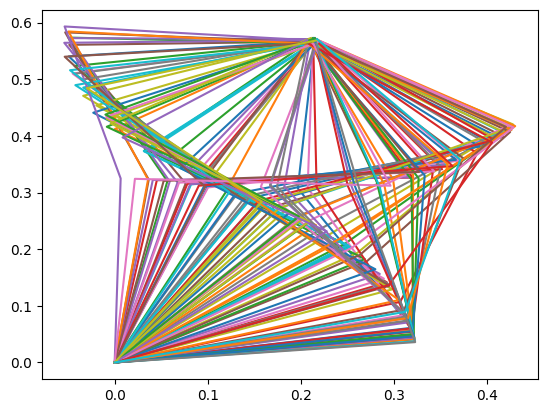

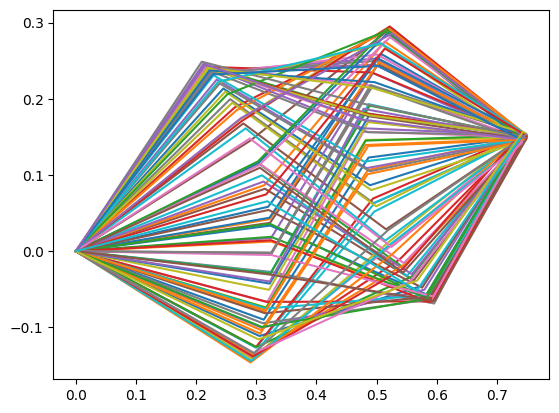

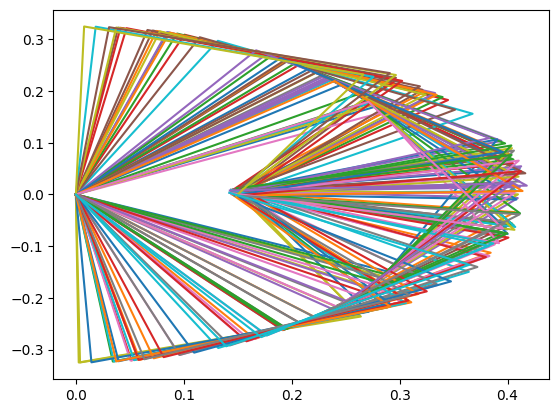

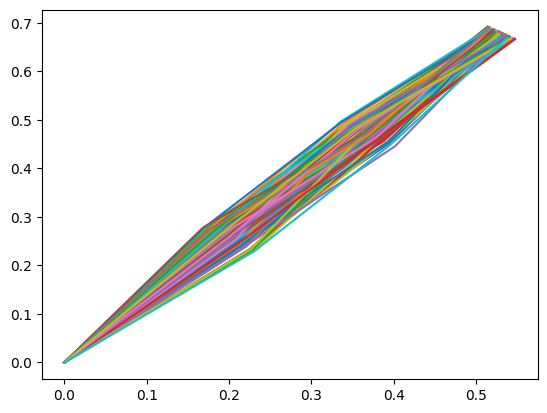

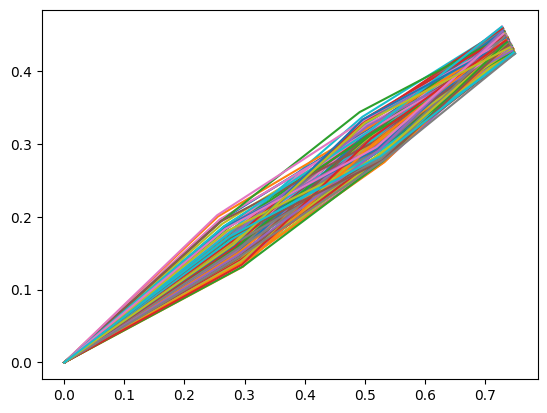

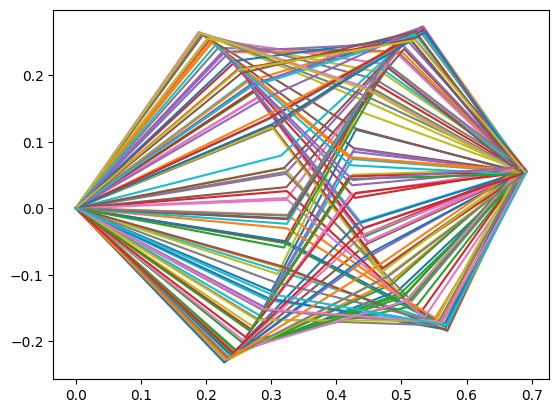

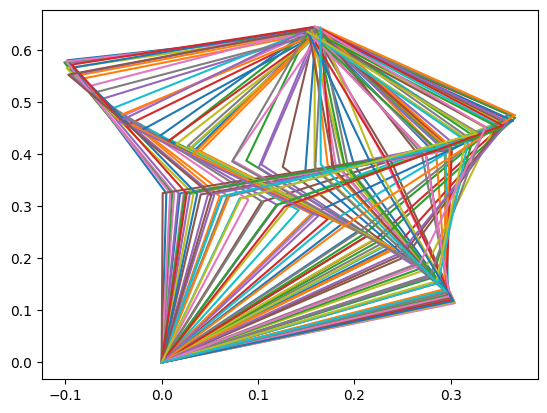

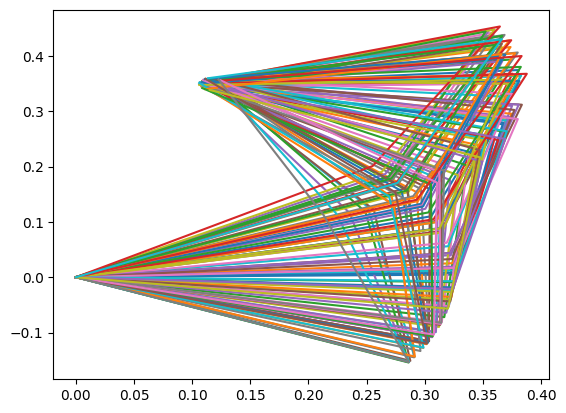

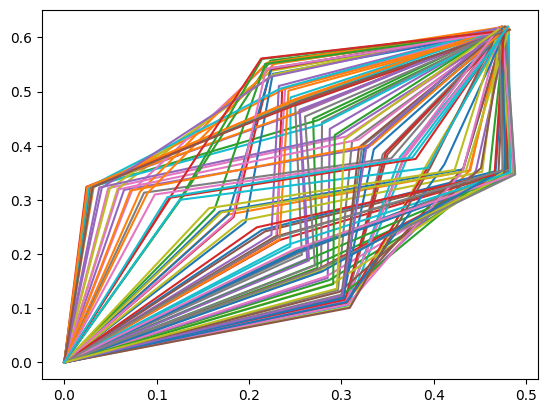

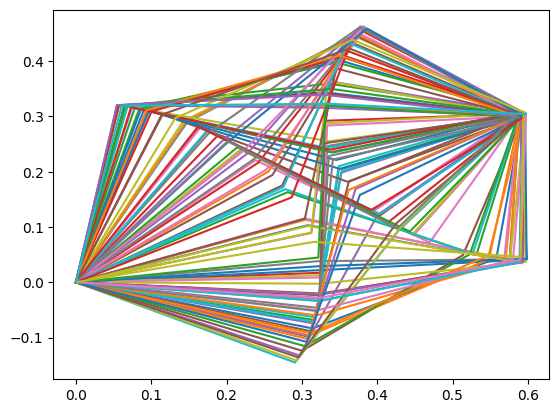

In [10]:
from matplotlib import pyplot as plt
for i in range(0,10):
    candicates,distance=distance_inverse_kinematics([np.random.uniform(0,sum(lengths)) for i in range(0,2)])
    # random_angle=[np.random.uniform(*angle) for angle in limits]
    # plt.plot(*forward_kinematics(random_angle,lengths).T)
    for i in candicates:
        val=forward_kinematics(i,lengths)
        plt.plot(*val.T)
    plt.show()




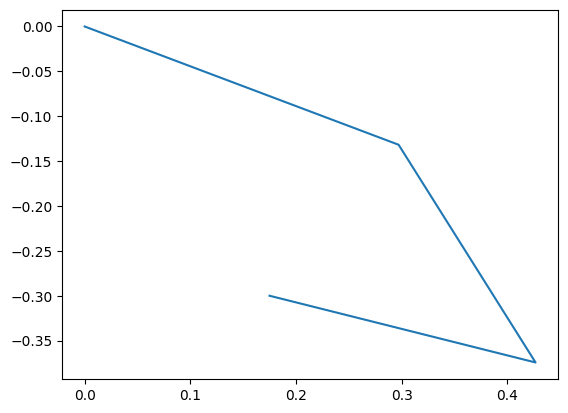

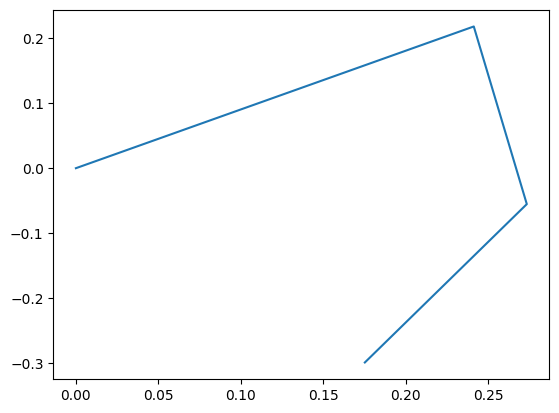

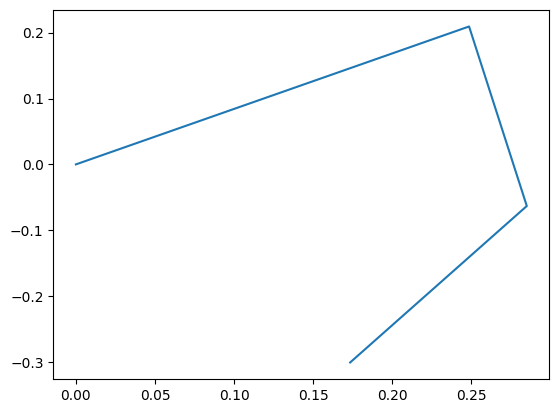

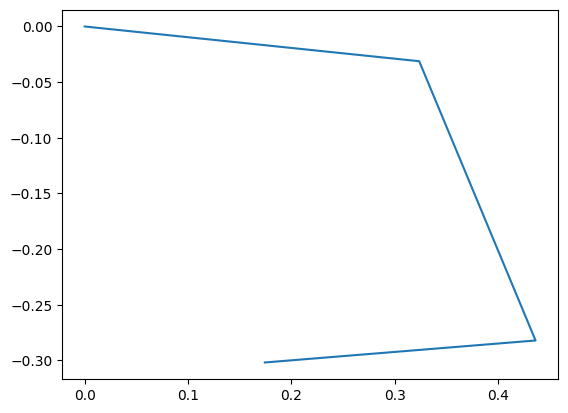

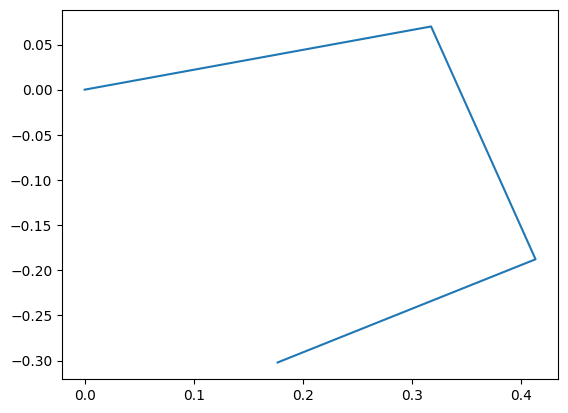

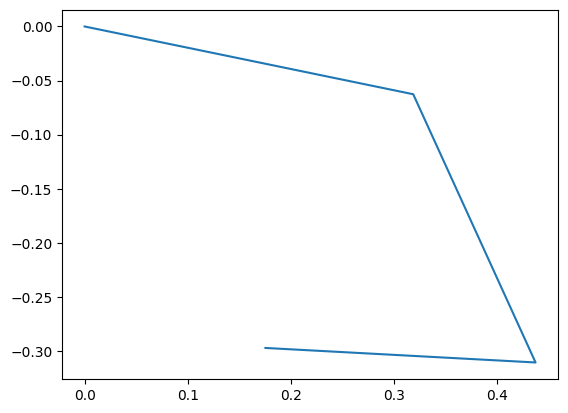

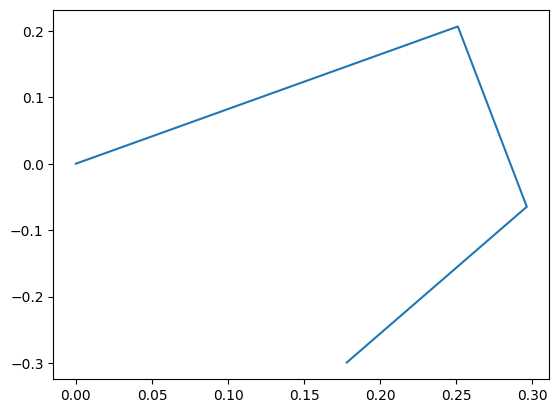

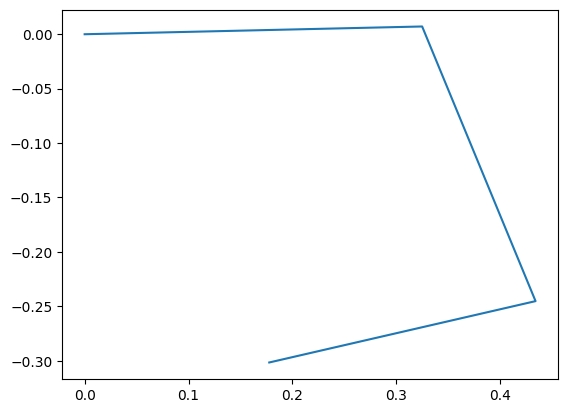

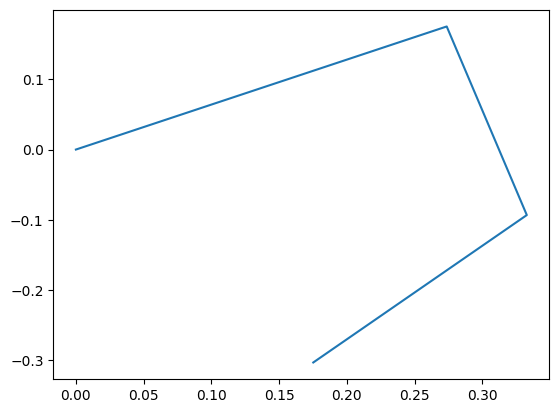

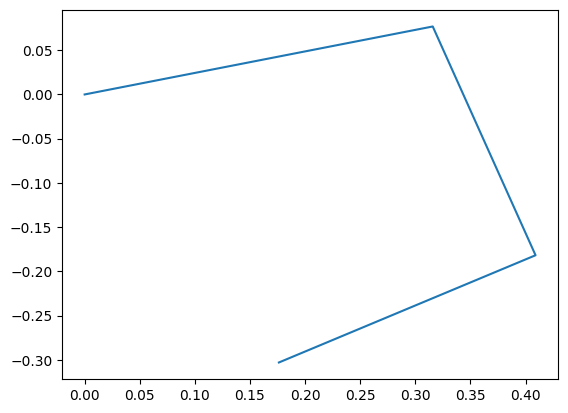

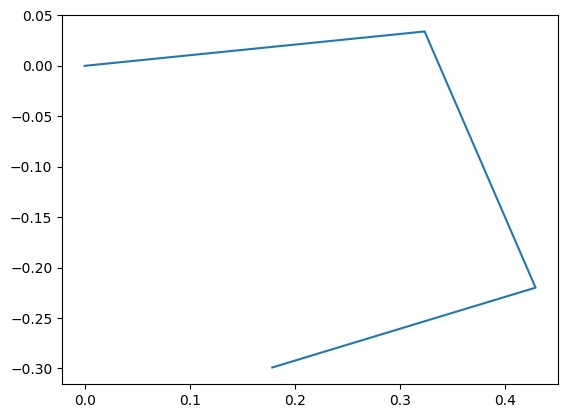

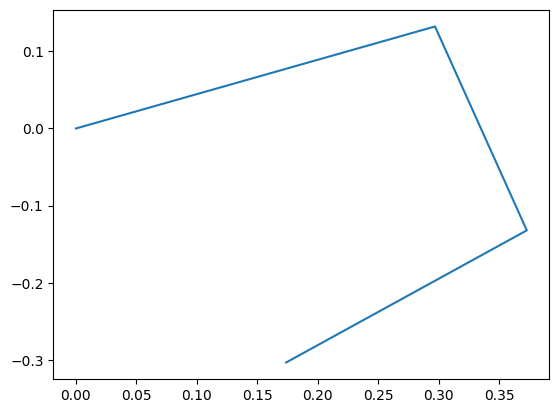

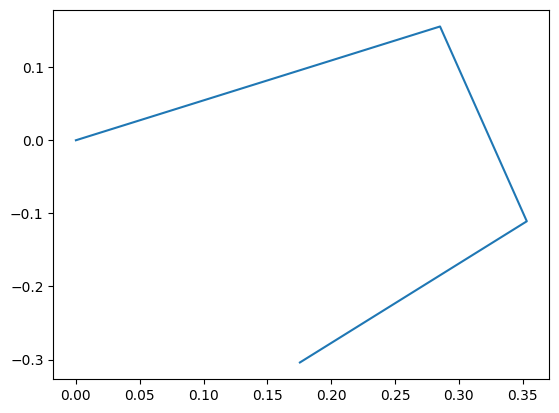

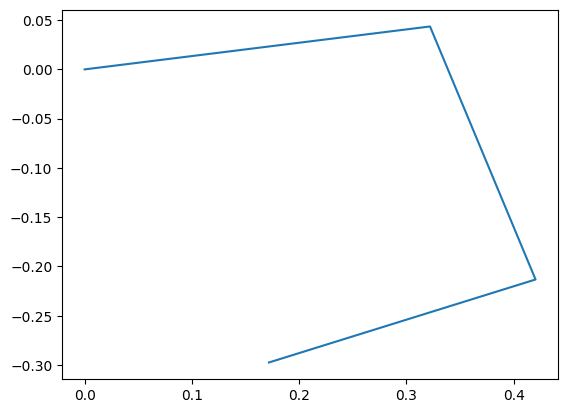

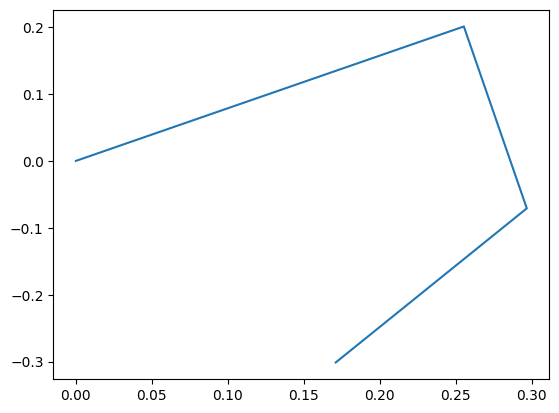

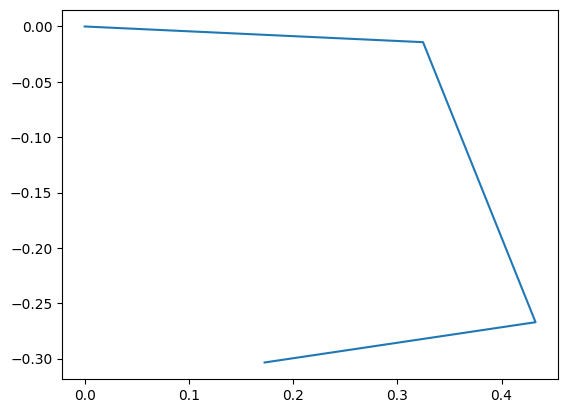

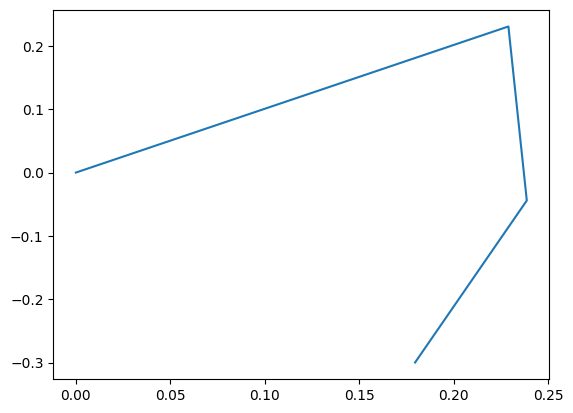

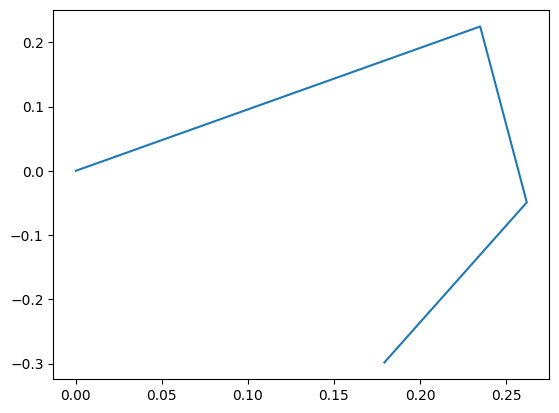

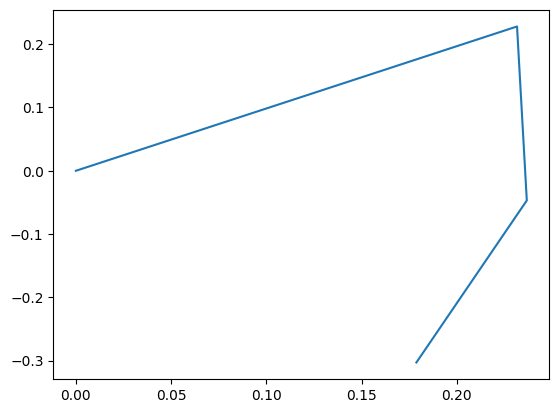

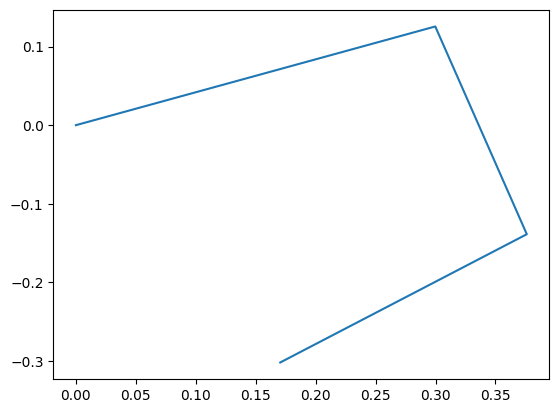

In [11]:
from matplotlib import pyplot as plt
candicates,distance=distance_inverse_kinematics([0.175,-0.3],k=20)
# random_angle=[np.random.uniform(*angle) for angle in limits]
# plt.plot(*forward_kinematics(random_angle,lengths).T)
for i in candicates:
    val=forward_kinematics(i,lengths)
    plt.plot(*val.T)
    plt.show()


